# EDA — Siniestros Viales de Bogotá D.C. (Unión de fuentes)

Este cuaderno une y analiza dos fuentes de datos abiertos sobre siniestralidad vial en Bogotá D.C.:

1. **`DATO_ABIERTOS_siniestros_viales_consolidados_bogota_dc (3).xlsx`** — archivo oficial "Datos Abiertos" con 5 hojas relacionales: `SINIESTROS`, `ACTOR_VIAL`, `VEHICULOS`, `HIPOTESIS` y `DICCIONARIO` (codificación de valores).
2. **`historico_siniestros_bogota_d_c_-.csv`** — histórico consolidado de siniestros con coordenadas geográficas (`LATITUD`, `LONGITUD`).

Ambas fuentes comparten la llave **`CODIGO_ACCIDENTE`**, que identifica un siniestro. Se usa para:
- Unir el histórico georreferenciado (CSV) con el detalle oficial del siniestro (hoja `SINIESTROS`).
- Enriquecer cada siniestro con información agregada de actores viales, vehículos involucrados y causas (hipótesis), agregadas desde las otras hojas del Excel.

Estructura del cuaderno:

1. Diccionario de variables (CSV y cada hoja del Excel)
2. Carga de datos
3. Preparación y unión de los datasets por `CODIGO_ACCIDENTE`
4. EDA general del dataset unido
5. Análisis temporal
6. Análisis por gravedad, clase, causas y actores
7. Mapa de zonas con accidentes
8. Resumen y hallazgos clave


## 1. Diccionario de variables

### 1.1 `historico_siniestros_bogota_d_c_-.csv`

199.146 registros. Un registro = un siniestro georreferenciado.

| Variable | Tipo | Descripción |
|---|---|---|
| `X` | float | Coordenada X (idéntica a `LONGITUD`), grados decimales EPSG:4326. |
| `Y` | float | Coordenada Y (idéntica a `LATITUD`), grados decimales EPSG:4326. |
| `OBJECTID` | int | Identificador interno del registro en el sistema de origen. |
| `FORMULARIO` | str | Número del formulario / acta policial (FURIPS/IPAT) asociado al siniestro. |
| `CODIGO_ACCIDENTE` | int | **Llave de unión.** Identificador único del siniestro, compartido con el archivo Excel. |
| `FECHA_OCURRENCIA_ACC` | str/fecha | Fecha en que ocurrió el siniestro. |
| `ANO_OCURRENCIA_ACC` | int | Año de ocurrencia (2015–2021). |
| `DIRECCION` | str | Dirección / nomenclatura vial donde ocurrió el siniestro. |
| `GRAVEDAD` | str | Gravedad del siniestro: `SOLO DAÑOS`, `CON HERIDOS`, `CON MUERTOS`. |
| `CLASE_ACC` | str | Clase de siniestro: `CHOQUE`, `ATROPELLO`, `CAIDA DE OCUPANTE`, `VOLCAMIENTO`, `OTRO`, `INCENDIO`, `AUTOLESION`. |
| `LOCALIDAD` | str | Localidad de Bogotá donde ocurrió el siniestro (46 nulos). |
| `FECHA_HORA_ACC` | str/fecha-hora | Fecha y hora completa del siniestro. |
| `LATITUD` | float | Latitud del siniestro (EPSG:4326). |
| `LONGITUD` | float | Longitud del siniestro (EPSG:4326). |
| `CIV` | float | Código de Identificación Vial del segmento donde ocurrió (1.701 nulos). |
| `PK_CALZADA` | float | Punto kilométrico sobre la calzada (37.974 nulos, alta tasa de faltantes). |

### 1.2 `SINIESTROS` (hoja del Excel)

196.152 registros. Nivel de detalle: un siniestro. Los códigos se decodifican usando la hoja `DICCIONARIO` del mismo archivo.

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | **Llave de unión** con el CSV. |
| `FECHA` | str/fecha | Fecha de ocurrencia. |
| `HORA` | str | Hora de ocurrencia. |
| `GRAVEDAD` | int | Código de gravedad: `1`=Con Muertos, `2`=Con Heridos, `3`=Solo Daños. |
| `CLASE` | int | Código de clase de siniestro: `1`=Choque, `2`=Atropello, `3`=Volcamiento, `4`=Caída de ocupante, `5`=Incendio, `6`=Otro, `7`=Autolesión. |
| `CHOQUE` | float | Tipo de objeto contra el que se chocó (solo aplica si `CLASE`=Choque): `1`=Vehículo, `2`=Tren, `3`=Semoviente, `4`=Objeto Fijo. |
| `OBJETO_FIJO` | float | Detalle del objeto fijo golpeado (solo si `CHOQUE`=4): Muro, Poste, Árbol, Barandas, Semáforo, Inmueble, Hidrante, Valla/Señal, Tarima/Caseta, Vehículo estacionado, Otro. |
| `DIRECCION` | str | Dirección del siniestro. |
| `CODIGO_LOCALIDAD` | int | Código numérico de la localidad (1–20, incluye Sumapaz). |
| `DISENO_LUGAR` | int | Diseño del lugar donde ocurrió: Tramo de Vía, Intersección, Vía peatonal, Paso elevado/inferior/a nivel, Glorieta, Puente, Vía troncal, Lote/predio, Ciclorruta, Pontón, Túnel. |

### 1.3 `ACTOR_VIAL` (hoja del Excel)

422.417 registros. Nivel de detalle: una persona involucrada en un siniestro (varias por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | Llave que vincula al siniestro. |
| `CODIGO_ACCIDENTADO` | int | Identificador de la persona involucrada. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `CONDICION` | str | Rol de la persona: `CONDUCTOR`, `MOTOCICLISTA`, `PASAJERO/ACOMPAÑANTE`, `PEATON`, `CICLISTA`. |
| `ESTADO` | str | Estado de la persona tras el siniestro: `ILESO`, `HERIDO`, `MUERTO`. |
| `EDAD` | object | Edad de la persona (contiene inconsistencias de formato, se trata como texto en la fuente). |
| `SEXO` | str | Sexo reportado: `MASCULINO`, `FEMENINO`, `SIN INFORMACION`. |
| `VEHICULO` | str | Código del vehículo asociado (nulo para peatones — 23.447 nulos, coincide con el conteo de peatones). |

### 1.4 `VEHICULOS` (hoja del Excel)

371.606 registros. Nivel de detalle: un vehículo involucrado en un siniestro (varios por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | Llave que vincula al siniestro. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `VEHICULO` | str | Identificador del vehículo (formato `CODIGO_ACCIDENTE-n`). |
| `CLASE` | int | Clase de vehículo (27 categorías): Automóvil, Bus, Buseta, Camión/Furgón, Camioneta, Campero, Microbús, Motocicleta, Bicicleta, Bus Articulado, entre otros. |
| `SERVICIO` | int | Tipo de servicio del vehículo: `1`=Oficial, `2`=Público, `3`=Particular, `4`=Diplomático, `0`=Sin información. |
| `MODALIDAD` | int | Modalidad de transporte (Mixto, Carga, Pasajeros — Masivo/Colectivo/Individual/Escolar, etc.). |
| `ENFUGA` | str | Indica si el vehículo se dio a la fuga: `S`/`N`. |

### 1.5 `HIPOTESIS` (hoja del Excel)

233.820 registros. Nivel de detalle: una causa/hipótesis asociada a un siniestro (varias posibles por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | Llave que vincula al siniestro. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `CODIGO_CAUSA` | int | Código de causa probable del siniestro (~150 categorías agrupadas por actor: conductor en general, ciclista/motociclista, vehículo, vía, peatón, pasajero/acompañante). Ej.: `116`=Exceso de velocidad, `115`=Embriaguez o droga, `142`=Semáforo en rojo, `306`=Huecos, `409`=Cruzar sin observar. |

### 1.6 `DICCIONARIO` (hoja del Excel)

212 filas. Tabla de codificación oficial: `HOJA`, `CAMPO`, `CODIGO`, `DESCRIPCION`. Se usa programáticamente en este cuaderno para traducir todos los códigos numéricos anteriores a sus etiquetas de texto.


## 2. Carga de librerías y datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (9, 6)


In [2]:
FILE_XLSX = "DATO_ABIERTOS_siniestros_viales_consolidados_bogota_dc (3).xlsx"
FILE_CSV = "historico_siniestros_bogota_d_c_-.csv"

# Histórico georreferenciado
hist = pd.read_csv(FILE_CSV, encoding='utf-8-sig')

# Hojas del archivo oficial
siniestros = pd.read_excel(FILE_XLSX, sheet_name='SINIESTROS')
actor_vial = pd.read_excel(FILE_XLSX, sheet_name='ACTOR_VIAL')
vehiculos  = pd.read_excel(FILE_XLSX, sheet_name='VEHICULOS')
hipotesis  = pd.read_excel(FILE_XLSX, sheet_name='HIPOTESIS')
diccionario = pd.read_excel(FILE_XLSX, sheet_name='DICCIONARIO')

print("historico_siniestros (CSV):", hist.shape)
print("SINIESTROS   :", siniestros.shape)
print("ACTOR_VIAL   :", actor_vial.shape)
print("VEHICULOS    :", vehiculos.shape)
print("HIPOTESIS    :", hipotesis.shape)
print("DICCIONARIO  :", diccionario.shape)


historico_siniestros (CSV): (199146, 16)
SINIESTROS   : (196152, 10)
ACTOR_VIAL   : (422416, 8)
VEHICULOS    : (371605, 7)
HIPOTESIS    : (233819, 3)
DICCIONARIO  : (211, 4)


### 2.1 Vista previa de cada tabla

In [3]:
hist.head()

,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0


In [4]:
siniestros.head()

,CODIGO_ACCIDENTE,FECHA,HORA,GRAVEDAD,CLASE,CHOQUE,OBJETO_FIJO,DIRECCION,CODIGO_LOCALIDAD,DISENO_LUGAR
0,4401438,01/01/2015,01:05:00,2,2,NaN,NaN,KR 64A-CL 2C 02,16,2
1,4401449,01/01/2015,05:50:00,2,3,NaN,NaN,AV AVENIDA DEL SUR-KR 65A 41,7,1
2,4401430,01/01/2015,07:15:00,2,3,NaN,NaN,KR 19D-CL 62 S 02,19,1
3,4401453,01/01/2015,09:30:00,3,1,1.0,NaN,KR 79-CL 42F S 71,8,1
4,4401423,01/01/2015,09:45:00,2,1,1.0,NaN,CL 66A-KR 76 02,10,2


In [5]:
diccionario.head(10)

,HOJA,CAMPO,CODIGO,DESCRIPCION
0,SINIESTROS,GRAVEDAD,1,Con Muertos
1,SINIESTROS,GRAVEDAD,2,Con Heridos
2,SINIESTROS,GRAVEDAD,3,Solo Daños
3,SINIESTROS,CLASE,7,Autolesion
4,SINIESTROS,CLASE,1,Choque
5,SINIESTROS,CLASE,2,Atropello
6,SINIESTROS,CLASE,4,Caida de ocupante
7,SINIESTROS,CLASE,3,Volcamiento
8,SINIESTROS,CLASE,6,Otro
9,SINIESTROS,CLASE,5,Incendio


## 3. Preparación y unión de los datasets

### 3.1 Función de decodificación

Se construye un diccionario Python `{{(HOJA, CAMPO): {{codigo: descripcion}}}}` a partir de la hoja `DICCIONARIO`, para traducir los códigos numéricos de `SINIESTROS`, `VEHICULOS` e `HIPOTESIS` a texto legible.

In [6]:
def construir_mapa_diccionario(dicc):
    mapa = {}
    for _, row in dicc.iterrows():
        clave = (row['HOJA'], row['CAMPO'])
        mapa.setdefault(clave, {})[row['CODIGO']] = row['DESCRIPCION']
    return mapa

mapa_dicc = construir_mapa_diccionario(diccionario)

def decodificar(df, hoja, campo, nueva_col=None):
    nueva_col = nueva_col or f"{campo}_DESC"
    mapa = mapa_dicc.get((hoja, campo), {})
    df[nueva_col] = df[campo].map(mapa)
    return df

# Decodificar SINIESTROS
siniestros = decodificar(siniestros, 'SINIESTROS', 'GRAVEDAD')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CLASE')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CHOQUE')
siniestros = decodificar(siniestros, 'SINIESTROS', 'OBJETO_FIJO')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CODIGO_LOCALIDAD', 'LOCALIDAD_DESC')
siniestros = decodificar(siniestros, 'SINIESTROS', 'DISENO_LUGAR')

# Decodificar VEHICULOS
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'CLASE')
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'SERVICIO')
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'MODALIDAD')

# Decodificar HIPOTESIS
hipotesis = decodificar(hipotesis, 'HIPOTESIS', 'CODIGO_CAUSA')

siniestros[['GRAVEDAD','GRAVEDAD_DESC','CLASE','CLASE_DESC','DISENO_LUGAR','DISENO_LUGAR_DESC']].head()

,GRAVEDAD,GRAVEDAD_DESC,CLASE,CLASE_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC
0,2,Con Heridos,2,Atropello,2,Interseccion
1,2,Con Heridos,3,Volcamiento,1,Tramo de Via
2,2,Con Heridos,3,Volcamiento,1,Tramo de Via
3,3,Solo Daños,1,Choque,1,Tramo de Via
4,2,Con Heridos,1,Choque,2,Interseccion


### 3.2 Cobertura de la llave `CODIGO_ACCIDENTE` entre fuentes

Antes de unir, se revisa cuántos códigos coinciden entre el CSV histórico y la hoja `SINIESTROS` del Excel.

In [7]:
set_csv = set(hist['CODIGO_ACCIDENTE'])
set_xlsx = set(siniestros['CODIGO_ACCIDENTE'])

interseccion = set_csv & set_xlsx
solo_csv = set_csv - set_xlsx
solo_xlsx = set_xlsx - set_csv

print(f"Códigos únicos en CSV               : {len(set_csv):,}")
print(f"Códigos únicos en SINIESTROS (XLSX)  : {len(set_xlsx):,}")
print(f"En ambas fuentes (intersección)      : {len(interseccion):,}")
print(f"Solo en CSV (sin match en XLSX)      : {len(solo_csv):,}")
print(f"Solo en XLSX (sin match en CSV)      : {len(solo_xlsx):,}")

Códigos únicos en CSV               : 199,146
Códigos únicos en SINIESTROS (XLSX)  : 196,152
En ambas fuentes (intersección)      : 181,020
Solo en CSV (sin match en XLSX)      : 18,126
Solo en XLSX (sin match en CSV)      : 15,132


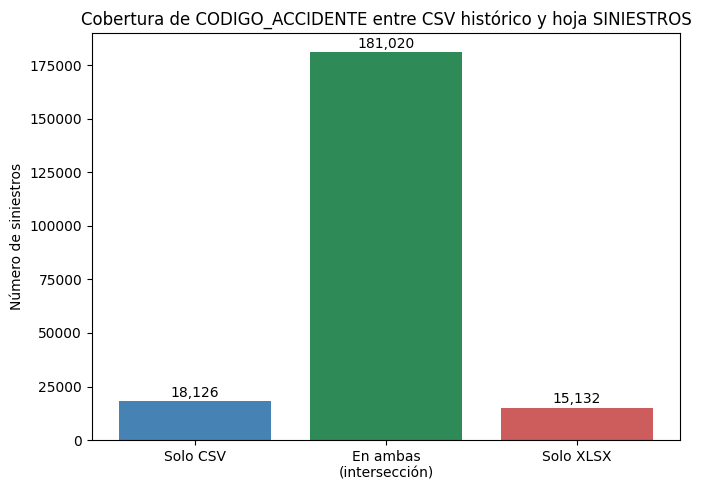

In [8]:
fig, ax = plt.subplots(figsize=(7,5))
labels = ['Solo CSV', 'En ambas\n(intersección)', 'Solo XLSX']
valores = [len(solo_csv), len(interseccion), len(solo_xlsx)]
ax.bar(labels, valores, color=['steelblue', 'seagreen', 'indianred'])
for i, v in enumerate(valores):
    ax.text(i, v + 2000, f"{v:,}", ha='center')
ax.set_title('Cobertura de CODIGO_ACCIDENTE entre CSV histórico y hoja SINIESTROS')
ax.set_ylabel('Número de siniestros')
plt.tight_layout()
plt.show()

### 3.3 Unión principal (CSV + SINIESTROS)

Se usa **`hist` (CSV) como tabla base**, porque es la única que trae coordenadas geográficas (`LATITUD`/`LONGITUD`), indispensables para el mapa. Se hace un `left join` con `SINIESTROS` por `CODIGO_ACCIDENTE`, para incorporar los campos adicionales que no están en el CSV: `CHOQUE`, `OBJETO_FIJO`, `DISENO_LUGAR` y sus descripciones.

In [9]:
cols_siniestros = ['CODIGO_ACCIDENTE', 'CHOQUE', 'CHOQUE_DESC', 'OBJETO_FIJO', 'OBJETO_FIJO_DESC',
                    'DISENO_LUGAR', 'DISENO_LUGAR_DESC']

df = hist.merge(siniestros[cols_siniestros], on='CODIGO_ACCIDENTE', how='left', indicator=True)

print("Registros del CSV con match en SINIESTROS:", (df['_merge'] == 'both').sum())
print("Registros del CSV SIN match en SINIESTROS:", (df['_merge'] == 'left_only').sum())
df = df.drop(columns='_merge')
print("\nShape del dataset unido:", df.shape)
df.head()

Registros del CSV con match en SINIESTROS: 181020
Registros del CSV SIN match en SINIESTROS: 18126

Shape del dataset unido: (199146, 22)


,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,CHOQUE,CHOQUE_DESC,OBJETO_FIJO,OBJETO_FIJO_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN,NaN,NaN,NaN,NaN,7.0,Glorieta
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0,1.0,Vehiculo,NaN,NaN,5.0,Paso inferior


### 3.4 Enriquecimiento con actores, vehículos y causas

Se agregan, por `CODIGO_ACCIDENTE`, resúmenes de las otras tres hojas y se incorporan al dataset unido:
- **Actores viales**: número de personas involucradas, número de muertos/heridos, sexo predominante.
- **Vehículos**: número de vehículos involucrados, clase de vehículo más frecuente.
- **Hipótesis**: causa principal reportada (la primera registrada por siniestro).

In [10]:
# Resumen de actores por accidente
agg_actores = actor_vial.groupby('CODIGO_ACCIDENTE').agg(
    N_ACTORES=('CODIGO_ACCIDENTADO', 'count'),
    N_MUERTOS=('ESTADO', lambda s: (s == 'MUERTO').sum()),
    N_HERIDOS=('ESTADO', lambda s: (s == 'HERIDO').sum()),
).reset_index()

# Resumen de vehículos por accidente
agg_vehiculos = vehiculos.groupby('CODIGO_ACCIDENTE').agg(
    N_VEHICULOS=('VEHICULO', 'count'),
).reset_index()
clase_top_vehiculo = (vehiculos.groupby('CODIGO_ACCIDENTE')['CLASE_DESC']
                       .agg(lambda s: s.value_counts().index[0] if len(s.dropna()) else np.nan)
                       .reset_index().rename(columns={'CLASE_DESC': 'CLASE_VEHICULO_PRINCIPAL'}))

# Causa principal por accidente (primera hipótesis registrada)
causa_principal = (hipotesis.sort_values('CODIGO_ACCIDENTE')
                   .groupby('CODIGO_ACCIDENTE')['CODIGO_CAUSA_DESC']
                   .first().reset_index().rename(columns={'CODIGO_CAUSA_DESC': 'CAUSA_PRINCIPAL'}))

df = (df.merge(agg_actores, on='CODIGO_ACCIDENTE', how='left')
        .merge(agg_vehiculos, on='CODIGO_ACCIDENTE', how='left')
        .merge(clase_top_vehiculo, on='CODIGO_ACCIDENTE', how='left')
        .merge(causa_principal, on='CODIGO_ACCIDENTE', how='left'))

print("Shape final del dataset unido y enriquecido:", df.shape)
df.head()

Shape final del dataset unido y enriquecido: (199146, 28)


,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,CHOQUE,CHOQUE_DESC,OBJETO_FIJO,OBJETO_FIJO_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC,N_ACTORES,N_MUERTOS,N_HERIDOS,N_VEHICULOS,CLASE_VEHICULO_PRINCIPAL,CAUSA_PRINCIPAL
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via,2.0,0.0,0.0,2.0,Camioneta,No mantener distancia de seguridad (conductor ...
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN,NaN,NaN,NaN,NaN,7.0,Glorieta,1.0,0.0,1.0,1.0,Motocicleta,Embriaguez aparente (conductor en general)
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via,2.0,0.0,0.0,2.0,"Camion, Furgon",Otra (conductor en general)
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via,2.0,0.0,0.0,2.0,"Camion, Furgon",Adelantar cerrando (conductor en general)
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0,1.0,Vehiculo,NaN,NaN,5.0,Paso inferior,2.0,0.0,0.0,2.0,Buseta,No mantener distancia de seguridad (conductor ...


### 3.5 Tipos de datos y parseo de fechas

In [11]:
df['FECHA_HORA_ACC'] = pd.to_datetime(df['FECHA_HORA_ACC'], errors='coerce')
df['FECHA_OCURRENCIA_ACC'] = pd.to_datetime(df['FECHA_OCURRENCIA_ACC'], errors='coerce')
df['MES'] = df['FECHA_HORA_ACC'].dt.month
df['DIA_SEMANA'] = df['FECHA_HORA_ACC'].dt.day_name()
df['HORA_DIA'] = df['FECHA_HORA_ACC'].dt.hour

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 199146 entries, 0 to 199145
Data columns (total 31 columns):
 #   Column                    Non-Null Count   Dtype              
---  ------                    --------------   -----              
 0   X                         199146 non-null  float64            
 1   Y                         199146 non-null  float64            
 2   OBJECTID                  199146 non-null  int64              
 3   FORMULARIO                199146 non-null  str                
 4   CODIGO_ACCIDENTE          199146 non-null  int64              
 5   FECHA_OCURRENCIA_ACC      199146 non-null  datetime64[us, UTC]
 6   ANO_OCURRENCIA_ACC        199146 non-null  int64              
 7   DIRECCION                 199146 non-null  str                
 8   GRAVEDAD                  199146 non-null  str                
 9   CLASE_ACC                 199146 non-null  str                
 10  LOCALIDAD                 199100 non-null  str                
 11  FECHA_HORA_

## 4. EDA general del dataset unido

### 4.1 Valores nulos

In [12]:
nulos = df.isna().sum().sort_values(ascending=False)
pct_nulos = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({'n_nulos': nulos, 'pct_nulos': pct_nulos})
resumen_nulos[resumen_nulos['n_nulos'] > 0]

,n_nulos,pct_nulos
OBJETO_FIJO_DESC,192921,96.87
OBJETO_FIJO,192914,96.87
CHOQUE_DESC,44573,22.38
CHOQUE,44306,22.25
PK_CALZADA,37974,19.07
CLASE_VEHICULO_PRINCIPAL,19066,9.57
CAUSA_PRINCIPAL,18516,9.30
N_ACTORES,18264,9.17
N_HERIDOS,18264,9.17
N_MUERTOS,18264,9.17


### 4.2 Estadística descriptiva

In [13]:
df.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
X,199146.0,-7.410410e+01,4.009853e-02,-7.422830e+01,-7.413420e+01,-7.410304e+01,-7.407301e+01,-7.401100e+01
Y,199146.0,4.649135e+00,5.756745e-02,4.085800e+00,4.608163e+00,4.645415e+00,4.690015e+00,4.828041e+00
OBJECTID,199146.0,2.461163e+05,1.282976e+05,1.000000e+00,1.356038e+05,2.830275e+05,3.581768e+05,4.219110e+05
CODIGO_ACCIDENTE,199146.0,7.368238e+06,3.017820e+06,4.401420e+06,4.458053e+06,4.512848e+06,1.049794e+07,1.054926e+07
ANO_OCURRENCIA_ACC,199146.0,2.017760e+03,1.855071e+00,2.015000e+03,2.016000e+03,2.018000e+03,2.019000e+03,2.021000e+03
LATITUD,199146.0,4.649135e+00,5.756745e-02,4.085800e+00,4.608163e+00,4.645415e+00,4.690015e+00,4.828041e+00
LONGITUD,199146.0,-7.410410e+01,4.009855e-02,-7.422830e+01,-7.413420e+01,-7.410304e+01,-7.407301e+01,-7.401100e+01
CIV,197445.0,1.379895e+07,1.346756e+07,0.000000e+00,7.004943e+06,1.000758e+07,1.500116e+07,5.000962e+07
PK_CALZADA,161172.0,7.588678e+06,1.840877e+07,0.000000e+00,4.326700e+04,1.769000e+05,2.354850e+05,9.103049e+07
CHOQUE,154840.0,1.128952e+00,6.128973e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00


### 4.3 Duplicados

In [14]:
print("Registros duplicados por CODIGO_ACCIDENTE:", df['CODIGO_ACCIDENTE'].duplicated().sum())
print("Filas totalmente duplicadas:", df.duplicated().sum())

Registros duplicados por CODIGO_ACCIDENTE: 0


Filas totalmente duplicadas: 0


## 5. Análisis temporal

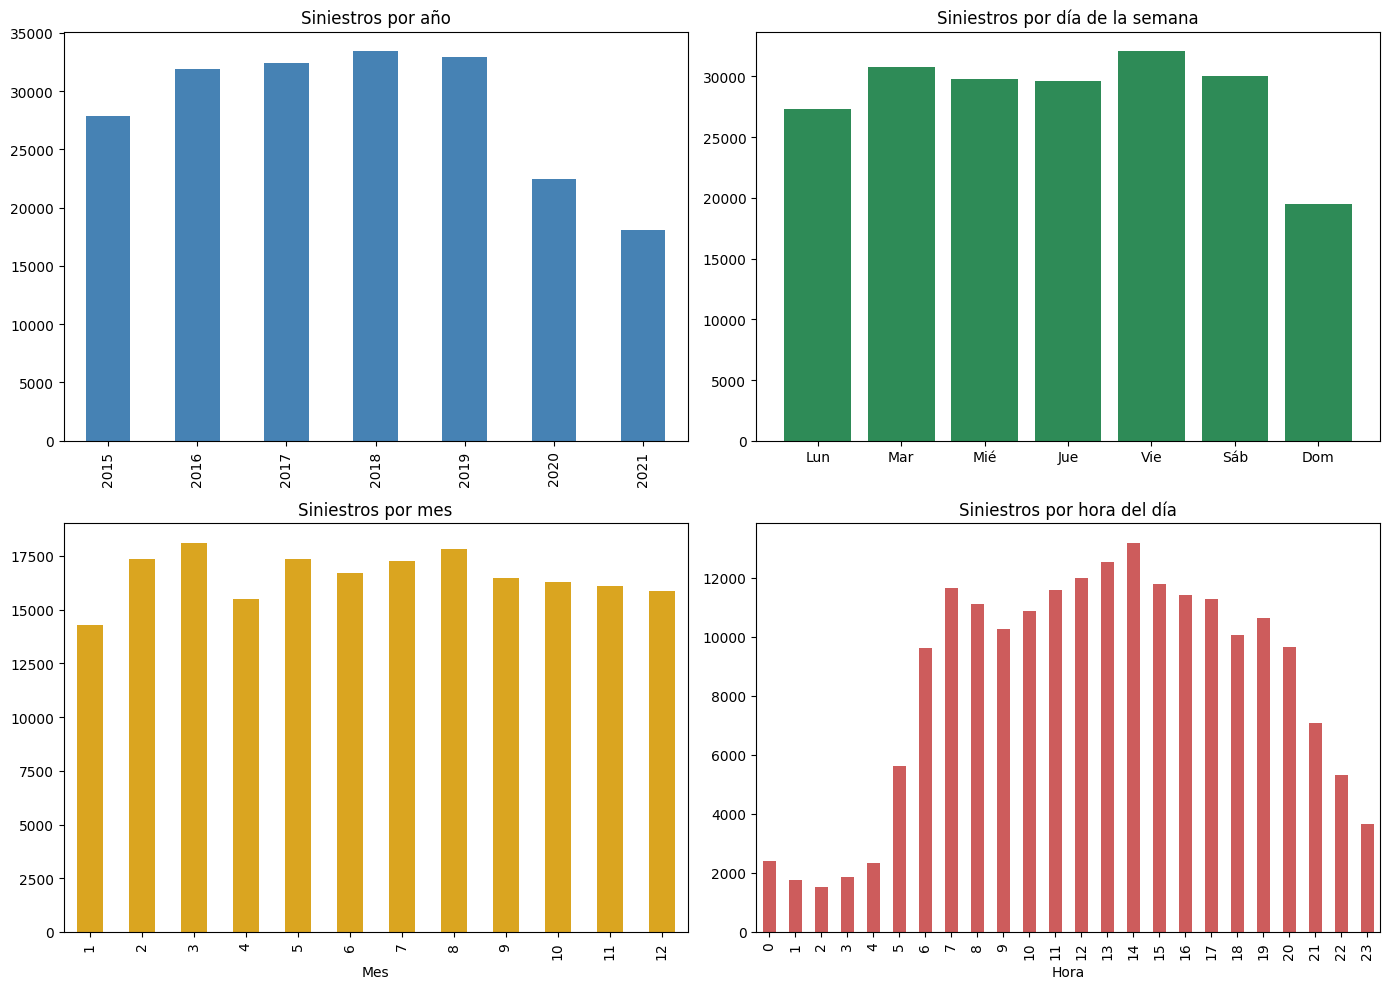

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df['ANO_OCURRENCIA_ACC'].value_counts().sort_index().plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Siniestros por año')
axes[0,0].set_xlabel('')

orden_dias = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
etiquetas_dias = ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']
conteo_dias = df['DIA_SEMANA'].value_counts().reindex(orden_dias)
axes[0,1].bar(etiquetas_dias, conteo_dias.values, color='seagreen')
axes[0,1].set_title('Siniestros por día de la semana')

df['MES'].value_counts().sort_index().plot(kind='bar', ax=axes[1,0], color='goldenrod')
axes[1,0].set_title('Siniestros por mes')
axes[1,0].set_xlabel('Mes')

df['HORA_DIA'].value_counts().sort_index().plot(kind='bar', ax=axes[1,1], color='indianred')
axes[1,1].set_title('Siniestros por hora del día')
axes[1,1].set_xlabel('Hora')

plt.tight_layout()
plt.show()

**Nota:** el pico visible en el gráfico "Siniestros por año" en los últimos años puede estar afectado por el hecho de que la hoja `SINIESTROS` del Excel solo cubre hasta 2020, mientras que el CSV llega hasta 2021; esto se refleja en el porcentaje de nulos de las columnas `CHOQUE`, `OBJETO_FIJO` y `DISENO_LUGAR` para 2021.

In [16]:
tabla_cobertura = df.groupby('ANO_OCURRENCIA_ACC')['DISENO_LUGAR'].apply(lambda s: s.notna().mean() * 100).round(1)
tabla_cobertura.to_frame('pct_con_match_en_SINIESTROS')

,pct_con_match_en_SINIESTROS
ANO_OCURRENCIA_ACC,
2015,100.0
2016,100.0
2017,100.0
2018,100.0
2019,100.0
2020,99.9
2021,0.0


## 6. Gravedad, clase de siniestro, causas y actores

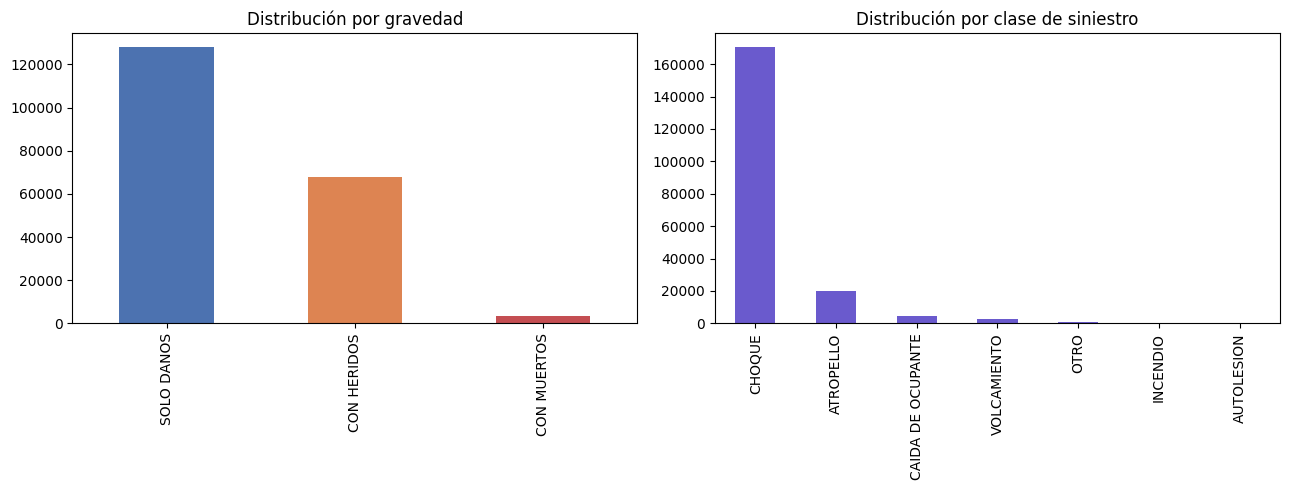

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

orden_gravedad = ['SOLO DANOS', 'CON HERIDOS', 'CON MUERTOS']
df['GRAVEDAD'].value_counts().reindex(orden_gravedad).plot(kind='bar', ax=axes[0], color=['#4c72b0','#dd8452','#c44e52'])
axes[0].set_title('Distribución por gravedad')
axes[0].set_xlabel('')

df['CLASE_ACC'].value_counts().plot(kind='bar', ax=axes[1], color='slateblue')
axes[1].set_title('Distribución por clase de siniestro')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

In [18]:
print(df['GRAVEDAD'].value_counts())
print()
print(df['CLASE_ACC'].value_counts())

GRAVEDAD
SOLO DANOS     128207
CON HERIDOS     67700
CON MUERTOS      3239
Name: count, dtype: int64

CLASE_ACC
CHOQUE               170802
ATROPELLO             20138
CAIDA DE OCUPANTE      4639
VOLCAMIENTO            2729
OTRO                    804
INCENDIO                 24
AUTOLESION               10
Name: count, dtype: int64


### 6.1 Diseño del lugar y tipo de choque

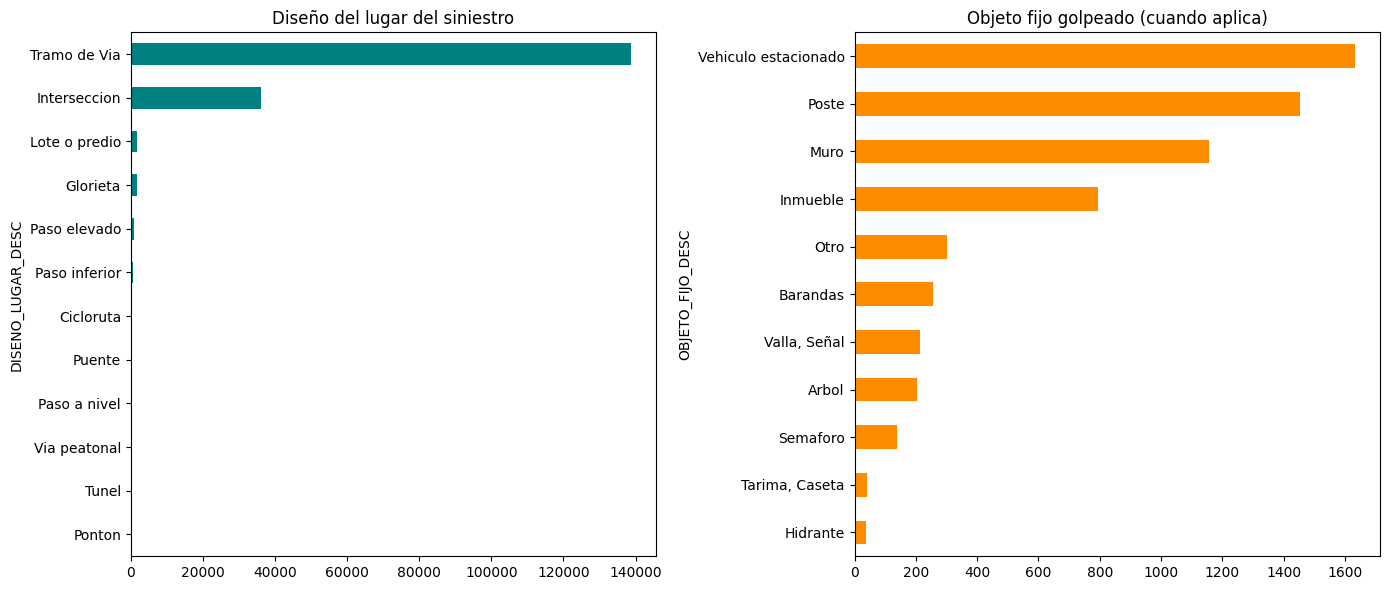

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

df['DISENO_LUGAR_DESC'].value_counts().plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Diseño del lugar del siniestro')
axes[0].invert_yaxis()

df['OBJETO_FIJO_DESC'].value_counts().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Objeto fijo golpeado (cuando aplica)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### 6.2 Causas principales de los siniestros

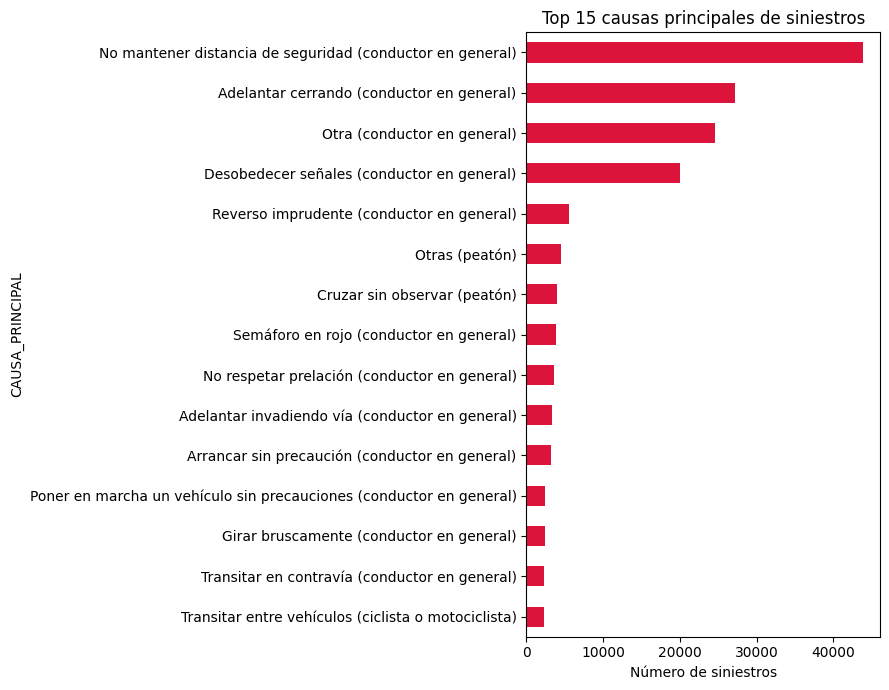

In [20]:
top_causas = df['CAUSA_PRINCIPAL'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(9,7))
top_causas.sort_values().plot(kind='barh', ax=ax, color='crimson')
ax.set_title('Top 15 causas principales de siniestros')
ax.set_xlabel('Número de siniestros')
plt.tight_layout()
plt.show()

### 6.3 Actores involucrados y clase de vehículo

           N_ACTORES      N_MUERTOS      N_HERIDOS    N_VEHICULOS
count  180882.000000  180882.000000  180882.000000  180882.000000
mean        2.154294       0.016608       0.484581       1.894252
std         0.779280       0.131464       0.949803       0.500304
min         1.000000       0.000000       0.000000       1.000000
25%         2.000000       0.000000       0.000000       2.000000
50%         2.000000       0.000000       0.000000       2.000000
75%         2.000000       0.000000       1.000000       2.000000
max        75.000000       4.000000      72.000000      30.000000


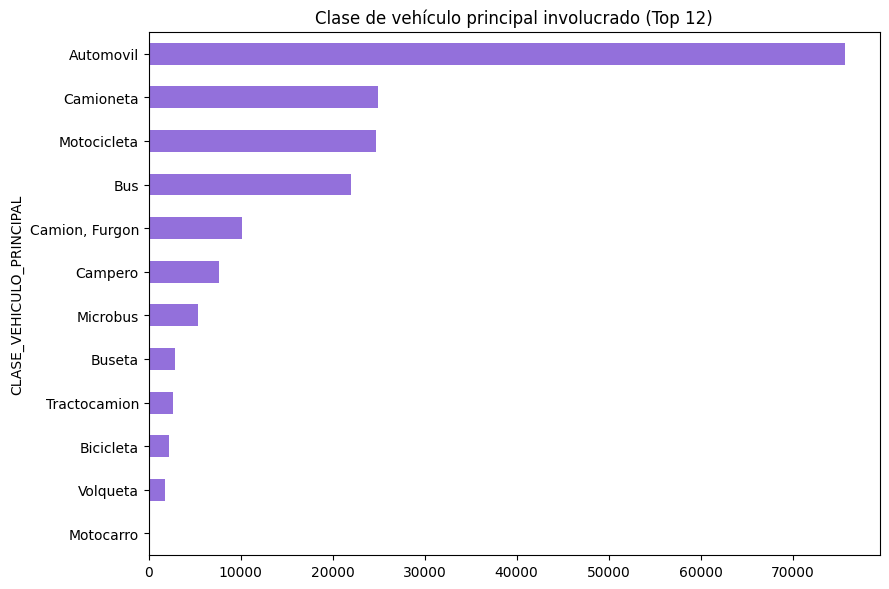

In [21]:
print(df[['N_ACTORES', 'N_MUERTOS', 'N_HERIDOS', 'N_VEHICULOS']].describe())

fig, ax = plt.subplots(figsize=(9,6))
df['CLASE_VEHICULO_PRINCIPAL'].value_counts().head(12).sort_values().plot(kind='barh', ax=ax, color='mediumpurple')
ax.set_title('Clase de vehículo principal involucrado (Top 12)')
plt.tight_layout()
plt.show()

### 6.4 Siniestros por localidad

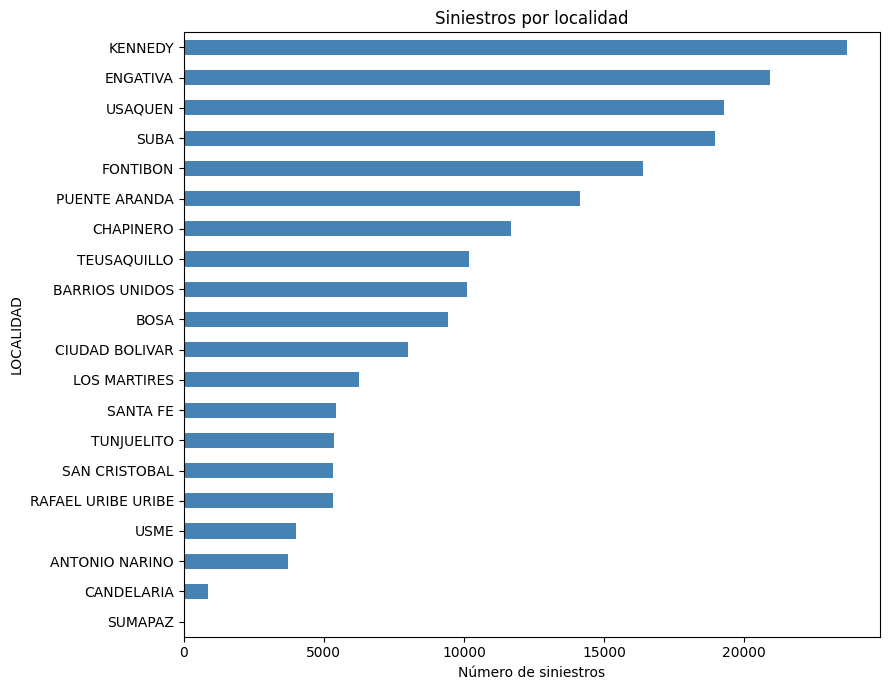

In [22]:
fig, ax = plt.subplots(figsize=(9,7))
df['LOCALIDAD'].value_counts().sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Siniestros por localidad')
ax.set_xlabel('Número de siniestros')
plt.tight_layout()
plt.show()

### 6.5 Gravedad por localidad (tabla cruzada)

In [23]:
tabla_grav_loc = pd.crosstab(df['LOCALIDAD'], df['GRAVEDAD'])
tabla_grav_loc = tabla_grav_loc[orden_gravedad]
tabla_grav_loc['TOTAL'] = tabla_grav_loc.sum(axis=1)
tabla_grav_loc.sort_values('TOTAL', ascending=False)

GRAVEDAD,SOLO DANOS,CON HERIDOS,CON MUERTOS,TOTAL
LOCALIDAD,,,,
KENNEDY,13596,9605,460,23661
ENGATIVA,14169,6466,293,20928
USAQUEN,15009,4121,162,19292
SUBA,12478,6234,261,18973
FONTIBON,12000,4141,236,16377
PUENTE ARANDA,9121,4790,232,14143
CHAPINERO,8906,2696,94,11696
TEUSAQUILLO,7196,2860,111,10167
BARRIOS UNIDOS,7228,2761,105,10094


## 7. Mapa de zonas con accidentes

Se usan las coordenadas `LATITUD`/`LONGITUD` del CSV (presentes en el 100% de los registros) para construir:

1. Un mapa de puntos coloreado por gravedad.
2. Un mapa de densidad (hexbin) que resalta las **zonas con mayor concentración de siniestros**.
3. Un mapa de densidad exclusivo para siniestros **con muertos**, al ser el subconjunto de mayor interés para política pública.

In [24]:
coords_validas = df[['LATITUD','LONGITUD']].notna().all(axis=1).sum()
print(f"Registros con coordenadas válidas: {coords_validas:,} de {len(df):,} ({coords_validas/len(df)*100:.1f}%)")
print()
print(df[['LATITUD','LONGITUD']].describe())

Registros con coordenadas válidas: 199,146 de 199,146 (100.0%)

             LATITUD       LONGITUD
count  199146.000000  199146.000000
mean        4.649135     -74.104096
std         0.057567       0.040099
min         4.085800     -74.228300
25%         4.608163     -74.134196
50%         4.645415     -74.103043
75%         4.690015     -74.073007
max         4.828041     -74.011000


### 7.0 Recorte a la zona urbana

Un pequeño número de registros (~13 de 199.146) tiene coordenadas muy alejadas del área urbana de Bogotá (zonas rurales del sur / posibles errores de geocodificación). Al graficarlos, estiran la escala del mapa y dificultan ver el detalle de la ciudad. Se acotan los ejes a la zona urbana para los mapas siguientes; el dataset `df` **no se filtra**, solo se ajusta la vista.

In [25]:
LON_MIN, LON_MAX = -74.24, -73.99
LAT_MIN, LAT_MAX = 4.45, 4.84

fuera_de_rango = (~df['LONGITUD'].between(LON_MIN, LON_MAX)) | (~df['LATITUD'].between(LAT_MIN, LAT_MAX))
print(f"Registros fuera de la zona urbana acotada: {fuera_de_rango.sum()} de {len(df)}")

Registros fuera de la zona urbana acotada: 13 de 199146


### 7.1 Mapa de puntos por gravedad

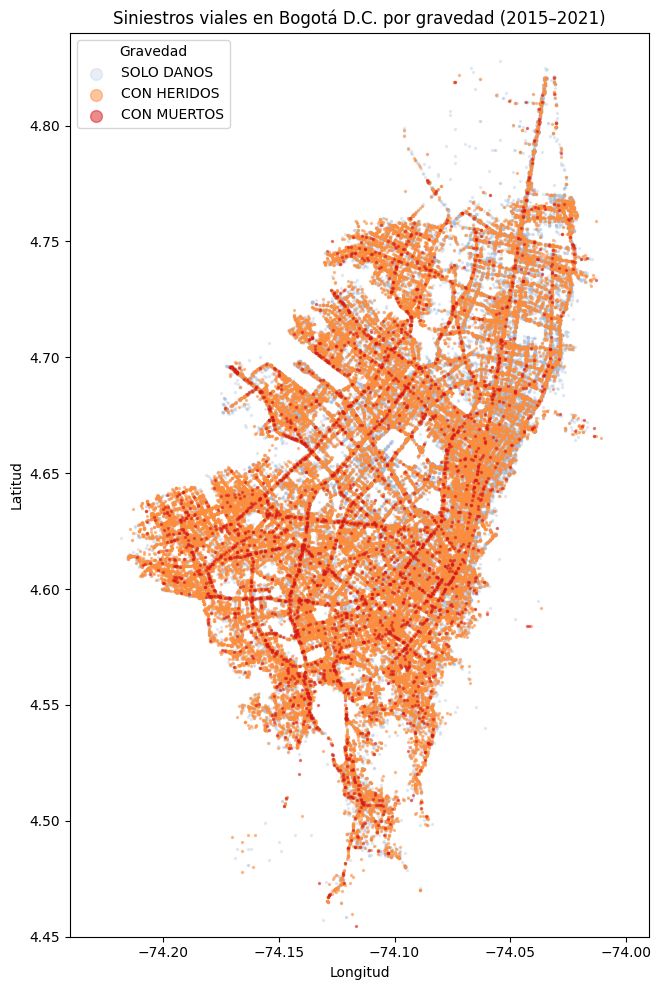

In [26]:
fig, ax = plt.subplots(figsize=(9, 10))

colores = {'SOLO DANOS': '#a6bddb', 'CON HERIDOS': '#fd8d3c', 'CON MUERTOS': '#d7191c'}
orden_plot = ['SOLO DANOS', 'CON HERIDOS', 'CON MUERTOS']  # dibujar muertos al final (encima)

for grav in orden_plot:
    sub = df[df['GRAVEDAD'] == grav]
    ax.scatter(sub['LONGITUD'], sub['LATITUD'], s=2, alpha=0.25 if grav=='SOLO DANOS' else 0.5,
               color=colores[grav], label=grav)

ax.set_title('Siniestros viales en Bogotá D.C. por gravedad (2015–2021)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
leg = ax.legend(markerscale=6, title='Gravedad')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

### 7.2 Mapa de densidad (zonas con mayor concentración de siniestros)

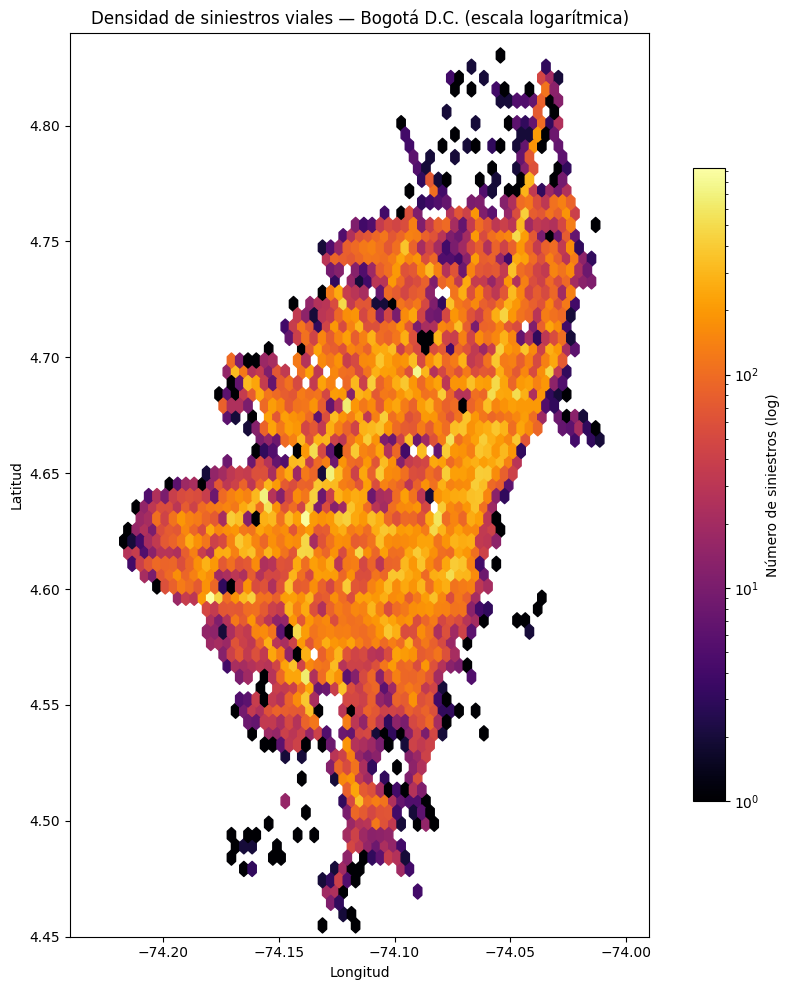

In [27]:
fig, ax = plt.subplots(figsize=(9, 10))

hb = ax.hexbin(df['LONGITUD'], df['LATITUD'], gridsize=70, cmap='inferno', mincnt=1, bins='log',
               extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_title('Densidad de siniestros viales — Bogotá D.C. (escala logarítmica)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
cb = fig.colorbar(hb, ax=ax, shrink=0.7)
cb.set_label('Número de siniestros (log)')
plt.tight_layout()
plt.show()

### 7.3 Mapa de densidad — solo siniestros con muertos

Siniestros con muertos: 3,239


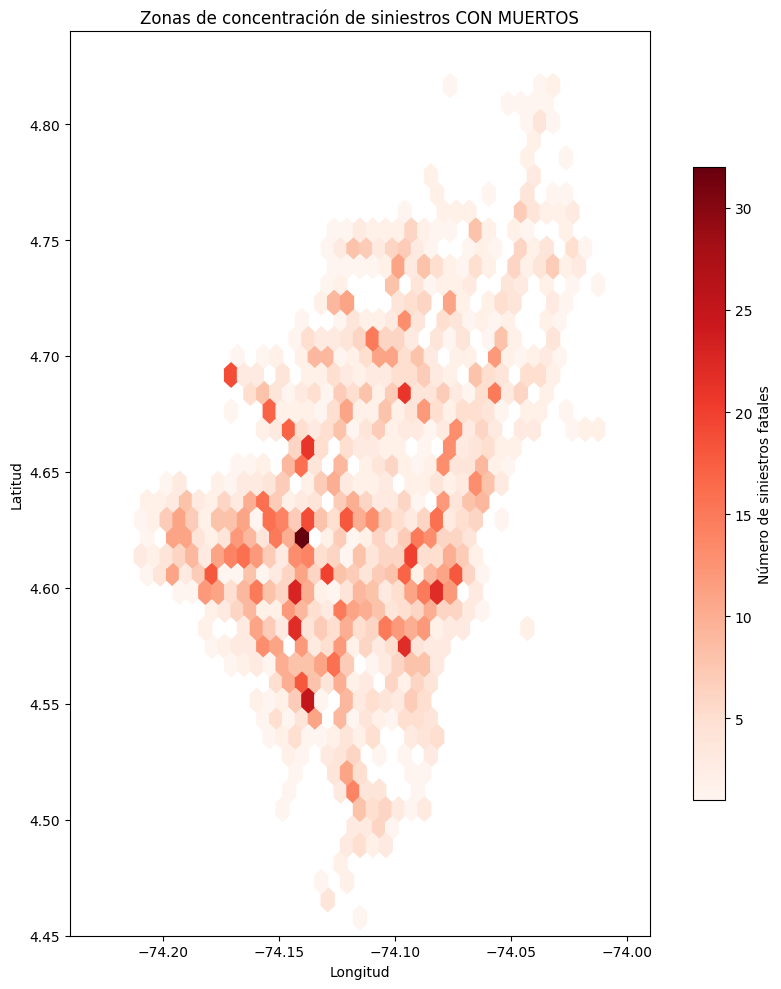

In [28]:
fatales = df[df['GRAVEDAD'] == 'CON MUERTOS']
print(f"Siniestros con muertos: {len(fatales):,}")

fig, ax = plt.subplots(figsize=(9, 10))
hb = ax.hexbin(fatales['LONGITUD'], fatales['LATITUD'], gridsize=45, cmap='Reds', mincnt=1,
               extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_title('Zonas de concentración de siniestros CON MUERTOS')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
cb = fig.colorbar(hb, ax=ax, shrink=0.7)
cb.set_label('Número de siniestros fatales')
plt.tight_layout()
plt.show()

### 7.4 Top 10 direcciones con más siniestros

Complementa el mapa identificando los puntos exactos (direcciones) más críticos.

In [29]:
df['DIRECCION'].value_counts().head(10).to_frame('N_SINIESTROS')

,N_SINIESTROS
DIRECCION,
KR 80-CL 2 51,213
AV AVENIDA BOYACA-CL 80 02,153
CL 13-KR 72 02,149
CL 100-KR 15 02,144
AV AVENIDA CIUDAD DE CALI-CL 26 02,140
AV AVENIDA BOYACA-CL 26 02,138
CL 80-KR 72 02,135
KR 50-CL 3 02,132
AV AVENIDA DEL SUR-CL 59 S 02,124


## 8. Resumen y hallazgos clave

**Unión de datasets**

- El CSV histórico (199.146 siniestros, 2015–2021) se usó como tabla base por ser la única fuente con coordenadas geográficas.
- Se unió con la hoja `SINIESTROS` del Excel (196.152 siniestros, 2015–2020) por `CODIGO_ACCIDENTE` mediante `left join`, obteniendo 181.020 coincidencias (~91% del CSV). Los registros sin match corresponden mayoritariamente a 2021, año no cubierto por el archivo Excel.
- Se enriqueció el dataset unido con agregados de `ACTOR_VIAL` (número de actores, muertos, heridos), `VEHICULOS` (número y clase de vehículos) e `HIPOTESIS` (causa principal), agregados a nivel de `CODIGO_ACCIDENTE`.

**Hallazgos generales**

- La gran mayoría de siniestros son **Solo Daños**; los siniestros **Con Muertos** son una fracción pequeña pero crítica del total.
- **Choque** es, por un margen amplio, la clase de siniestro más frecuente, seguida de **Atropello**.
- Existen patrones temporales claros: variación por día de la semana, mes del año y hora del día, útiles para focalizar controles viales.
- **Kennedy, Engativá, Usaquén y Suba** concentran el mayor número de siniestros, lo cual es consistente con su alta densidad vial y poblacional.
- El mapa de densidad permite identificar corredores viales específicos con alta concentración de siniestros, información más accionable que el conteo agregado por localidad.

**Limitaciones y próximos pasos**

1. El campo `EDAD` en `ACTOR_VIAL` contiene inconsistencias de formato y debe limpiarse antes de análisis demográfico más profundo.
2. `PK_CALZADA` y `CIV` en el CSV tienen tasas de nulos considerables; conviene evaluar si `CIV` permite vincular cada siniestro con un segmento específico de la Malla Vial Integral (ver cuaderno de EDA de la malla vial) para análisis de red.
3. El desbalance temporal entre fuentes (Excel hasta 2020, CSV hasta 2021) debe tenerse en cuenta al comparar tendencias interanuales recientes.
4. Se recomienda cruzar espacialmente los siniestros con la Malla Vial Integral y los Puentes (EDA previo) para relacionar siniestralidad con tipo de vía e infraestructura.
